# 02 · Reclamações: o que os jogadores dizem e como isso se liga à queda

Etapa 5 do projeto. Classifica as **416,8 mil análises da Steam** em temas de reclamação, valida a classificação lendo análises uma a uma e mede a relação de cada tema com o voto, com o abandono e com a queda de jogadores.

**Temas do escopo:** cheaters e hackers; ratos, campers e traição; bugs, travamentos e servidores; exploits e duplicação de itens; falta de PvE / excesso de PvP.
**Temas de contexto (adicionados):** falta de conteúdo e jogo abandonado; balanceamento; pareamento.

**Método**
1. Dicionário multilíngue (`src/analysis/complaints_lexicon.py`) cobrindo os 12 idiomas com mais análises (97% do total), com gírias da comunidade.
2. **Reclamação = análise negativa que menciona o tema.** Nas positivas os mesmos termos aparecem sobretudo em elogios ("sem bugs", "boa mistura de PvE e PvP").
3. Ajuste do dicionário numa amostra de 220 análises; **precisão medida numa segunda amostra, independente**, de 220 análises negativas lidas uma a uma (rótulos com justificativa em `data/external/complaint_validation_labels.csv`).
4. Impacto: regressões logísticas com controles (mês, horas jogadas, idioma), estudo das semanas pós-patch e correlação temporal com a variação de jogadores.

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image

sys.path.insert(0, str(Path.cwd().parent / "src"))
from analysis import complaints

complaints.cmd_tag()     # marca os temas (≈ 3 min)
complaints.cmd_report()  # gráficos e métricas
metrics = json.loads(Path("../reports/metrics_reclamacoes.json").read_text(encoding="utf-8"))

273,206 análises com 20+ caracteres
               todas_%  negativas_%  positivas_%
t_cheaters        5.29        16.80         1.53
t_rats            9.89        20.38         6.47
t_bugs            6.13        13.09         3.87
t_exploits        1.24         3.86         0.39
t_pve            11.19        21.06         7.98
t_content         2.03         4.97         1.08
t_balance         2.12         5.58         1.00
t_matchmaking     4.97        11.33         2.90
negativas sem nenhum tema: 41.8%
amostra de validação em C:\dev\arc-raiders-analysis\data\interim\validation_sample.csv


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figura: 08a_reclamacoes_mapa_de_calor.png
figura: 08b_reclamacoes_tendencia.png
figura: 08c_impacto_voto_e_abandono.png
figura: 08d_validacao_classificacao.png
figura: 08e_reclamacoes_x_jogadores.png
                                  tema  precisao  n_amostra  mencao_negativas  cobertura_estimada
0                   Cheaters e hackers      1.00         20             0.168               1.000
1             Ratos, campers e traição      1.00         20             0.204               0.807
2       Bugs, travamentos e servidores      0.85         20             0.131               0.800
3       Exploits e duplicação de itens      0.95         20             0.039               1.000
4        Falta de PvE / excesso de PvP      0.80         20             0.211               0.858
5  Falta de conteúdo e jogo abandonado      0.85         20             0.050               0.464
6        Balanceamento (nerfs e buffs)      1.00         20             0.056               1.000
7             Pa

## 1. A classificação é confiável?

| Tema | Precisão | Cobertura estimada |
|---|---|---|
| Cheaters e hackers | 100% | ~100% |
| Ratos, campers e traição | 100% | ~81% |
| Balanceamento | 100% | ~100% |
| Exploits e duplicação | 95% | ~100% |
| Bugs, travamentos e servidores | 85% | ~80% |
| Falta de conteúdo e jogo abandonado | 85% | **~46%** |
| Falta de PvE / excesso de PvP | 80% | ~86% |
| Pareamento | 75% | ~92% |

**Precisão geral: 90%** (144 de 160). A exceção é **conteúdo**: as pessoas descrevem a falta de novidades com paráfrases ("ran the game into the ground", "precisa de mais conteúdo"), e o dicionário encontra só cerca de metade. **Esse tema está subestimado em ~2x** em todos os números abaixo.

Com 20 análises por tema, cada ponto tem margem de ±10 a ±20 p.p.: a tabela separa temas bem medidos de temas frágeis, não dá o número exato. O ajuste foi feito numa amostra e medido em outra para não inflar a precisão; entre as correções encontradas no ajuste está um bug que apagava os espaços das frases do dicionário.

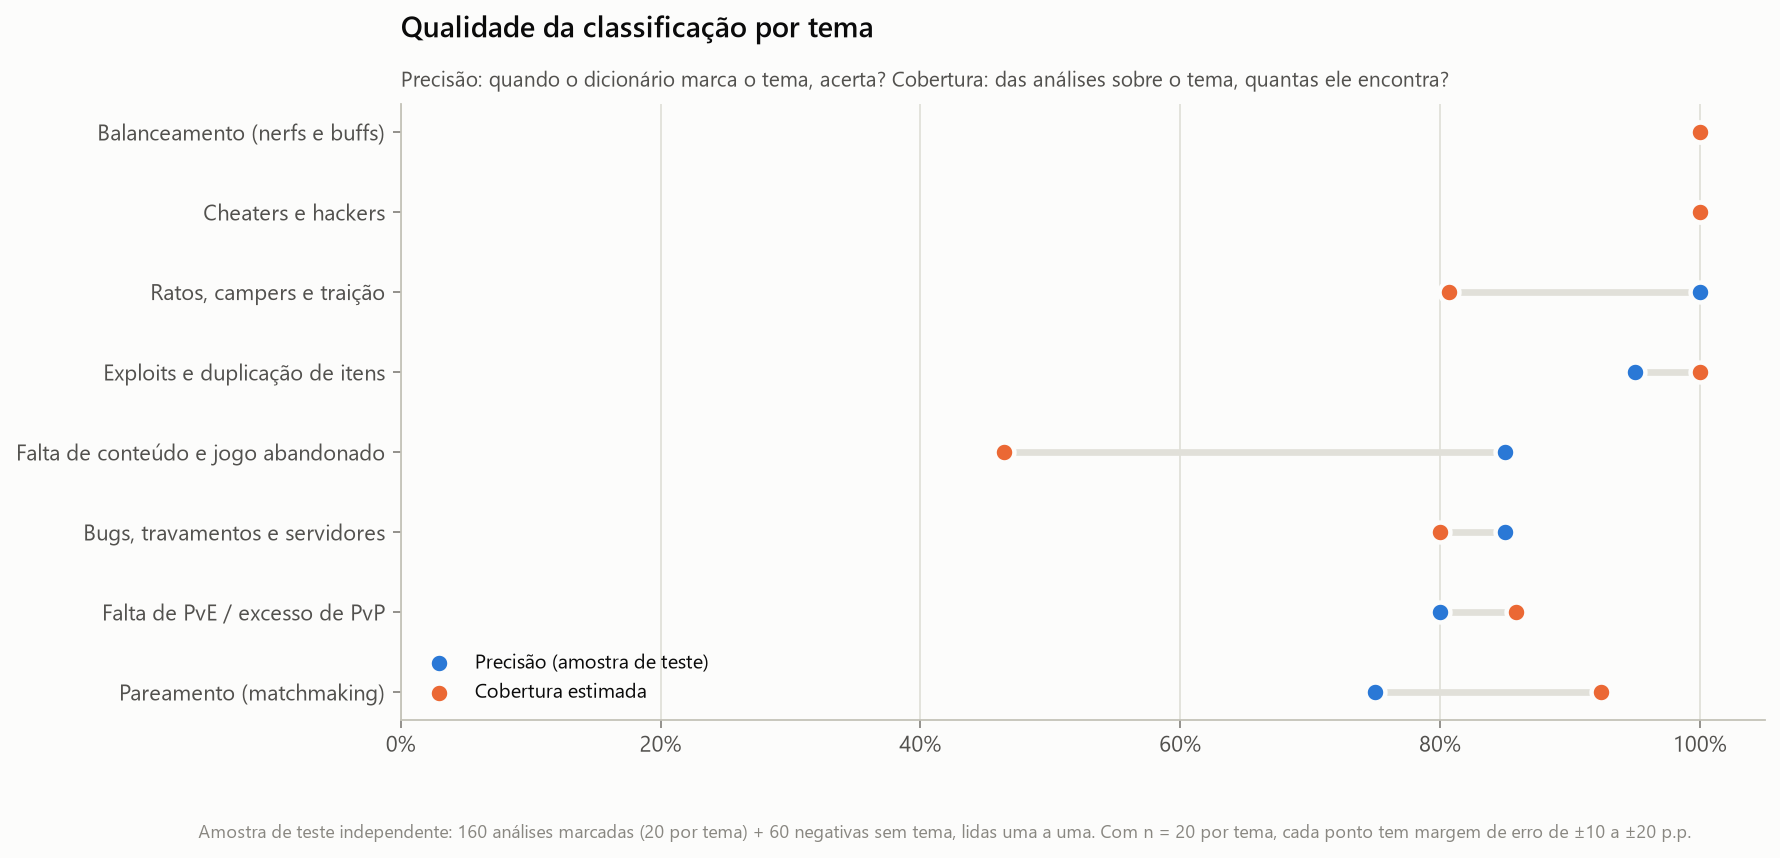

In [2]:
Image("../reports/figures/08d_validacao_classificacao.png")

## 2. Do que as análises negativas reclamam

A parcela de análises negativas (com texto) foi de 16% em nov/2025 para 57% em set/2026. Dentro delas, a mudança mais forte é **cheaters: de 9% para 43% das negativas**, com salto em jun/2026. Ratos e bugs perderam espaço relativo; falta de PvE ficou estável, em torno de 1 em cada 5 negativas, o ano inteiro.

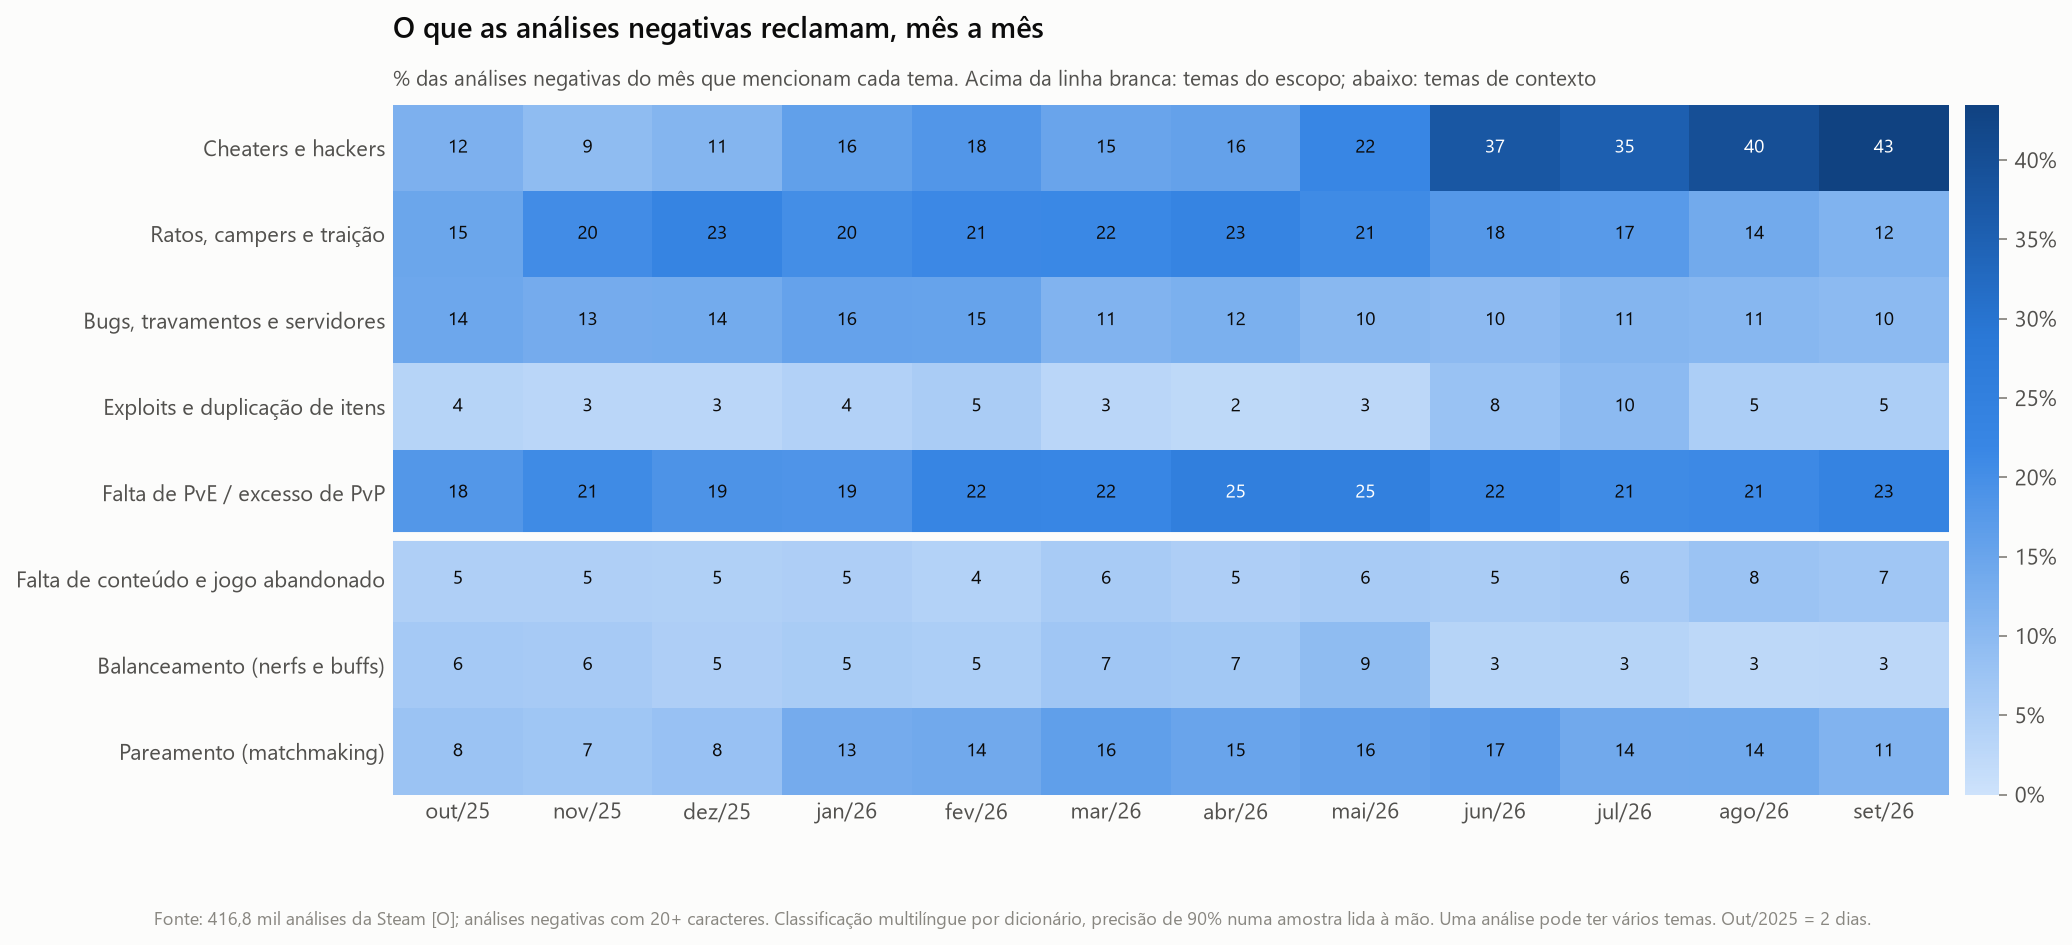

In [3]:
Image("../reports/figures/08a_reclamacoes_mapa_de_calor.png")

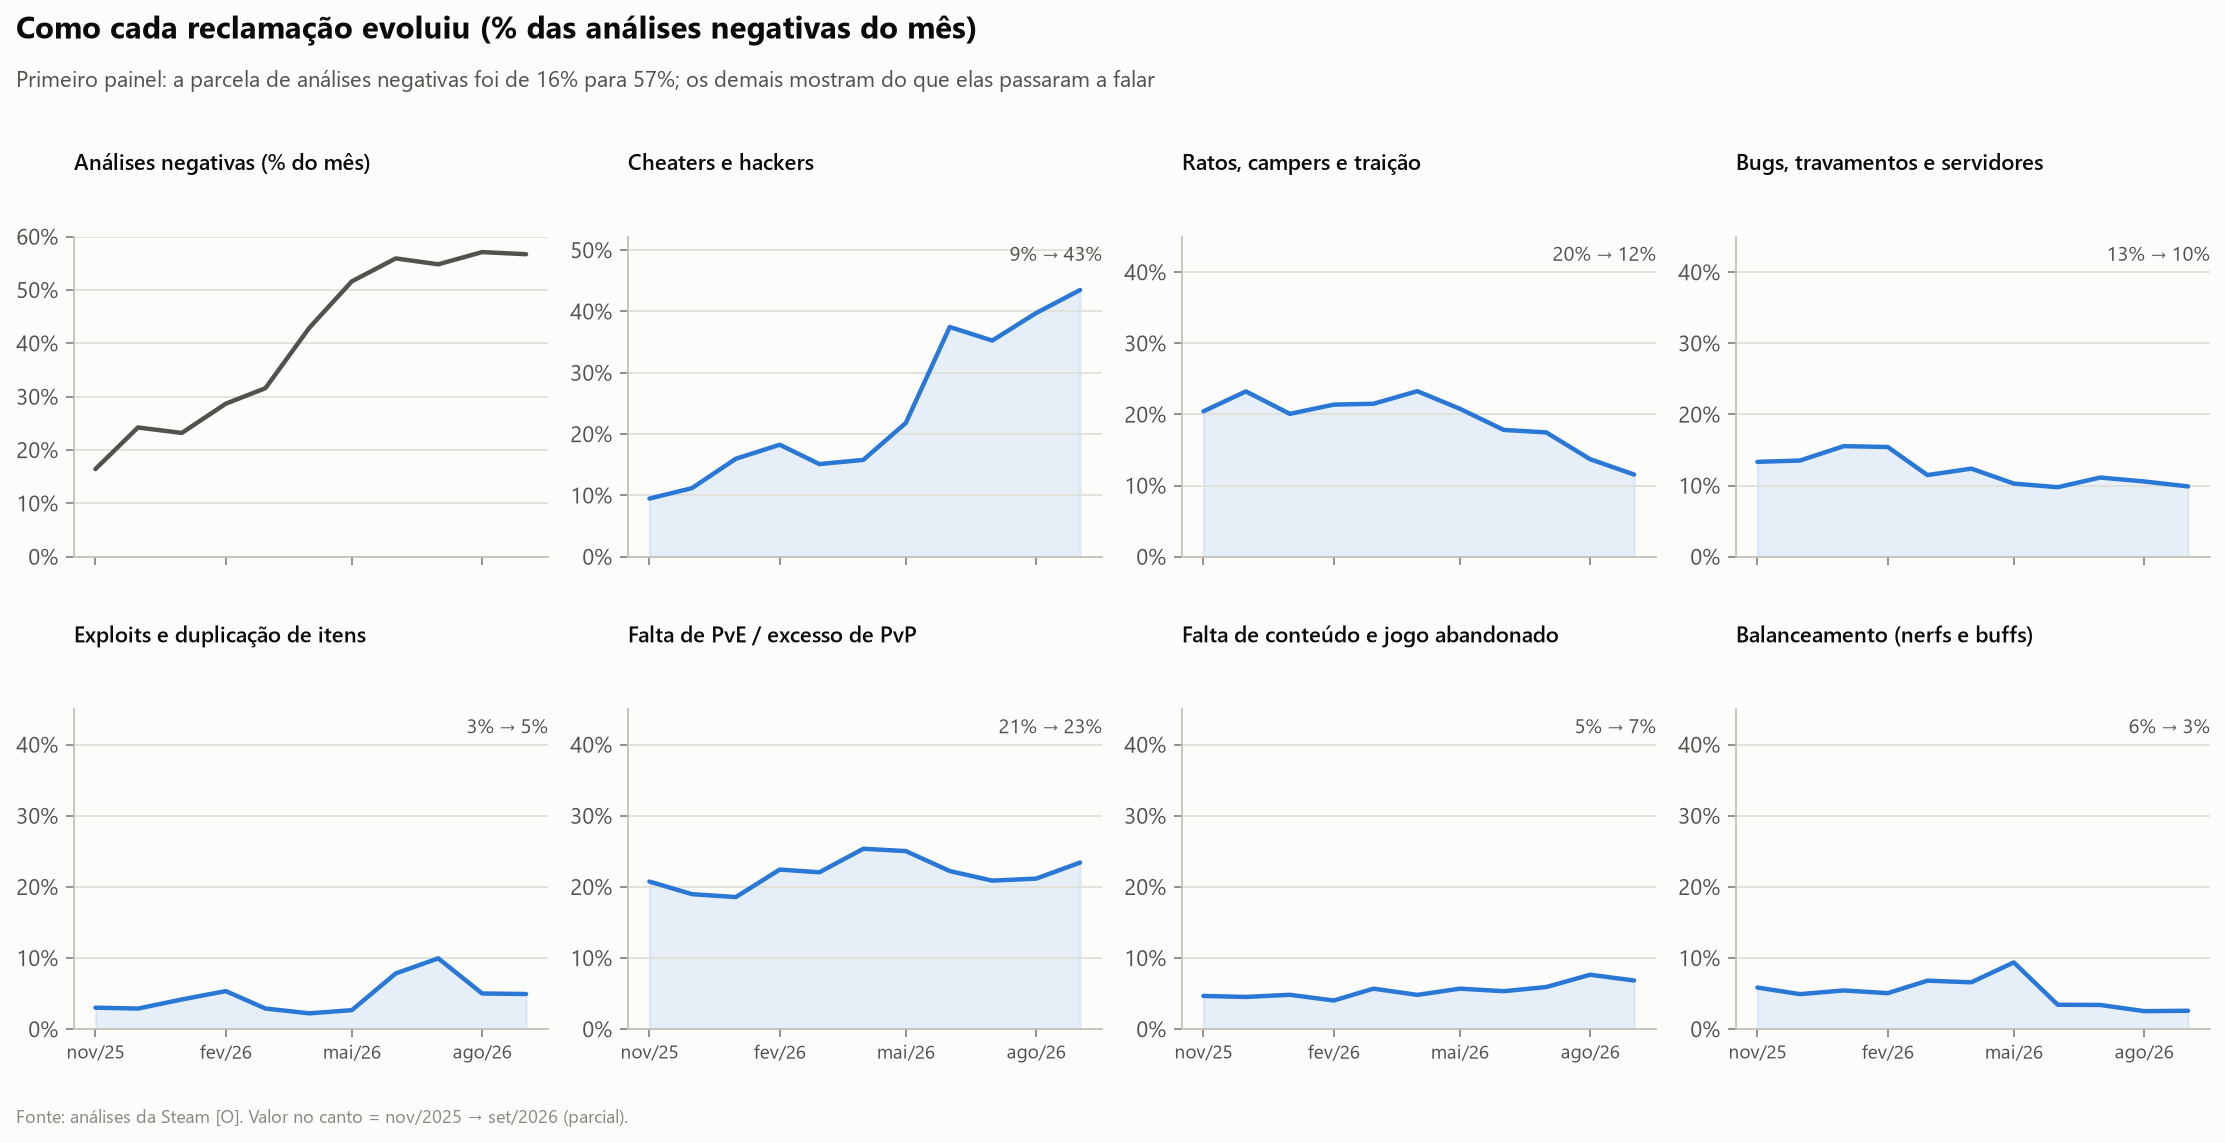

In [4]:
Image("../reports/figures/08b_reclamacoes_tendencia.png")

## 3. Quanto cada reclamação pesa

**No voto** (todas as análises, controlando mês, horas jogadas e idioma): mencionar **cheaters reduz em 28 p.p.** a chance de recomendar o jogo, quase o dobro de qualquer outro tema. Depois vêm balanceamento (−18), conteúdo (−16), bugs (−16) e ratos (−14). PvE (−10) e pareamento (−8) pesam menos: quem pede PvE muitas vezes ainda gosta do jogo.

**No abandono** (só análises negativas): **85% dos autores de análises negativas já não jogavam** nas duas semanas antes da coleta, qualquer que fosse a reclamação. Os temas quase não diferenciam quem saiu (efeitos de −1 a +2 p.p.). A exceção é **balanceamento (+1,9 p.p.)**: quem reclamou de nerfs saiu mais. Quem pede PvE ou reclama do pareamento tende a ainda estar jogando: são jogadores esperando uma mudança, o público-alvo do teste de PvE de outubro.

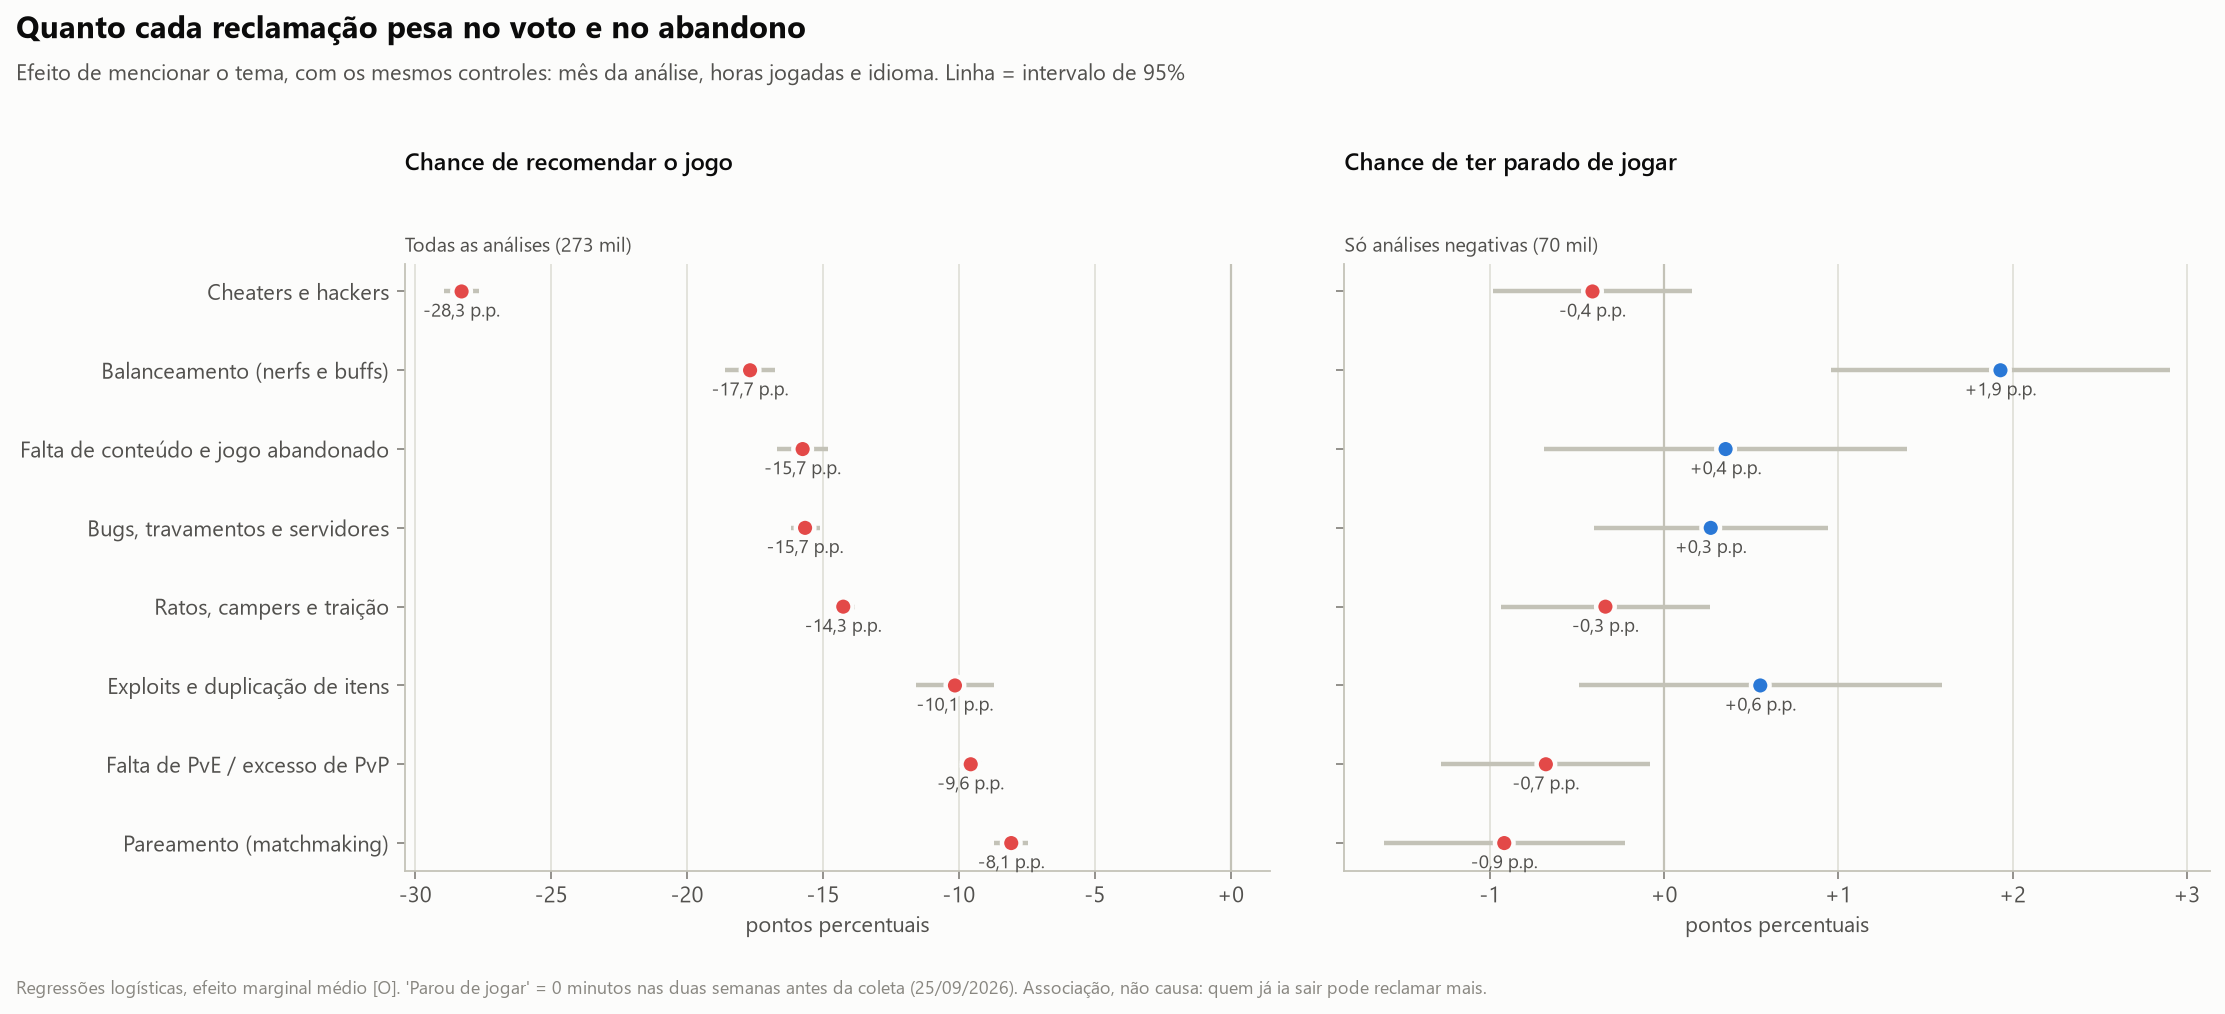

In [5]:
Image("../reports/figures/08c_impacto_voto_e_abandono.png")

## 4. Reclamações e a queda de jogadores

Por 100 análises do mês, as **reclamações de cheaters foram de 1,6 para 24,7** (16x). Mas elas explodiram *depois* da fase de queda mais rápida (fev–jun/2026): são sobretudo o motivo de saída de quem ficou, e o maior peso na nota atual.

O tema que **antecede** as quedas é **balanceamento**: correlação de −0,55 entre a taxa do mês e a variação de jogadores do mês seguinte. Isso bate com duas evidências independentes:
- no estudo de evento da Etapa 4, os patches de balanceamento ficaram em média 12% abaixo da tendência de jogadores;
- nas semanas após esses patches, **7,6%** das análises negativas falam de balanceamento, contra **4,8%** nas demais (+60%).

**Cuidado:** são 9 meses de dados; nenhuma correlação aqui é estatisticamente conclusiva sozinha. O peso da evidência vem da convergência das três análises.

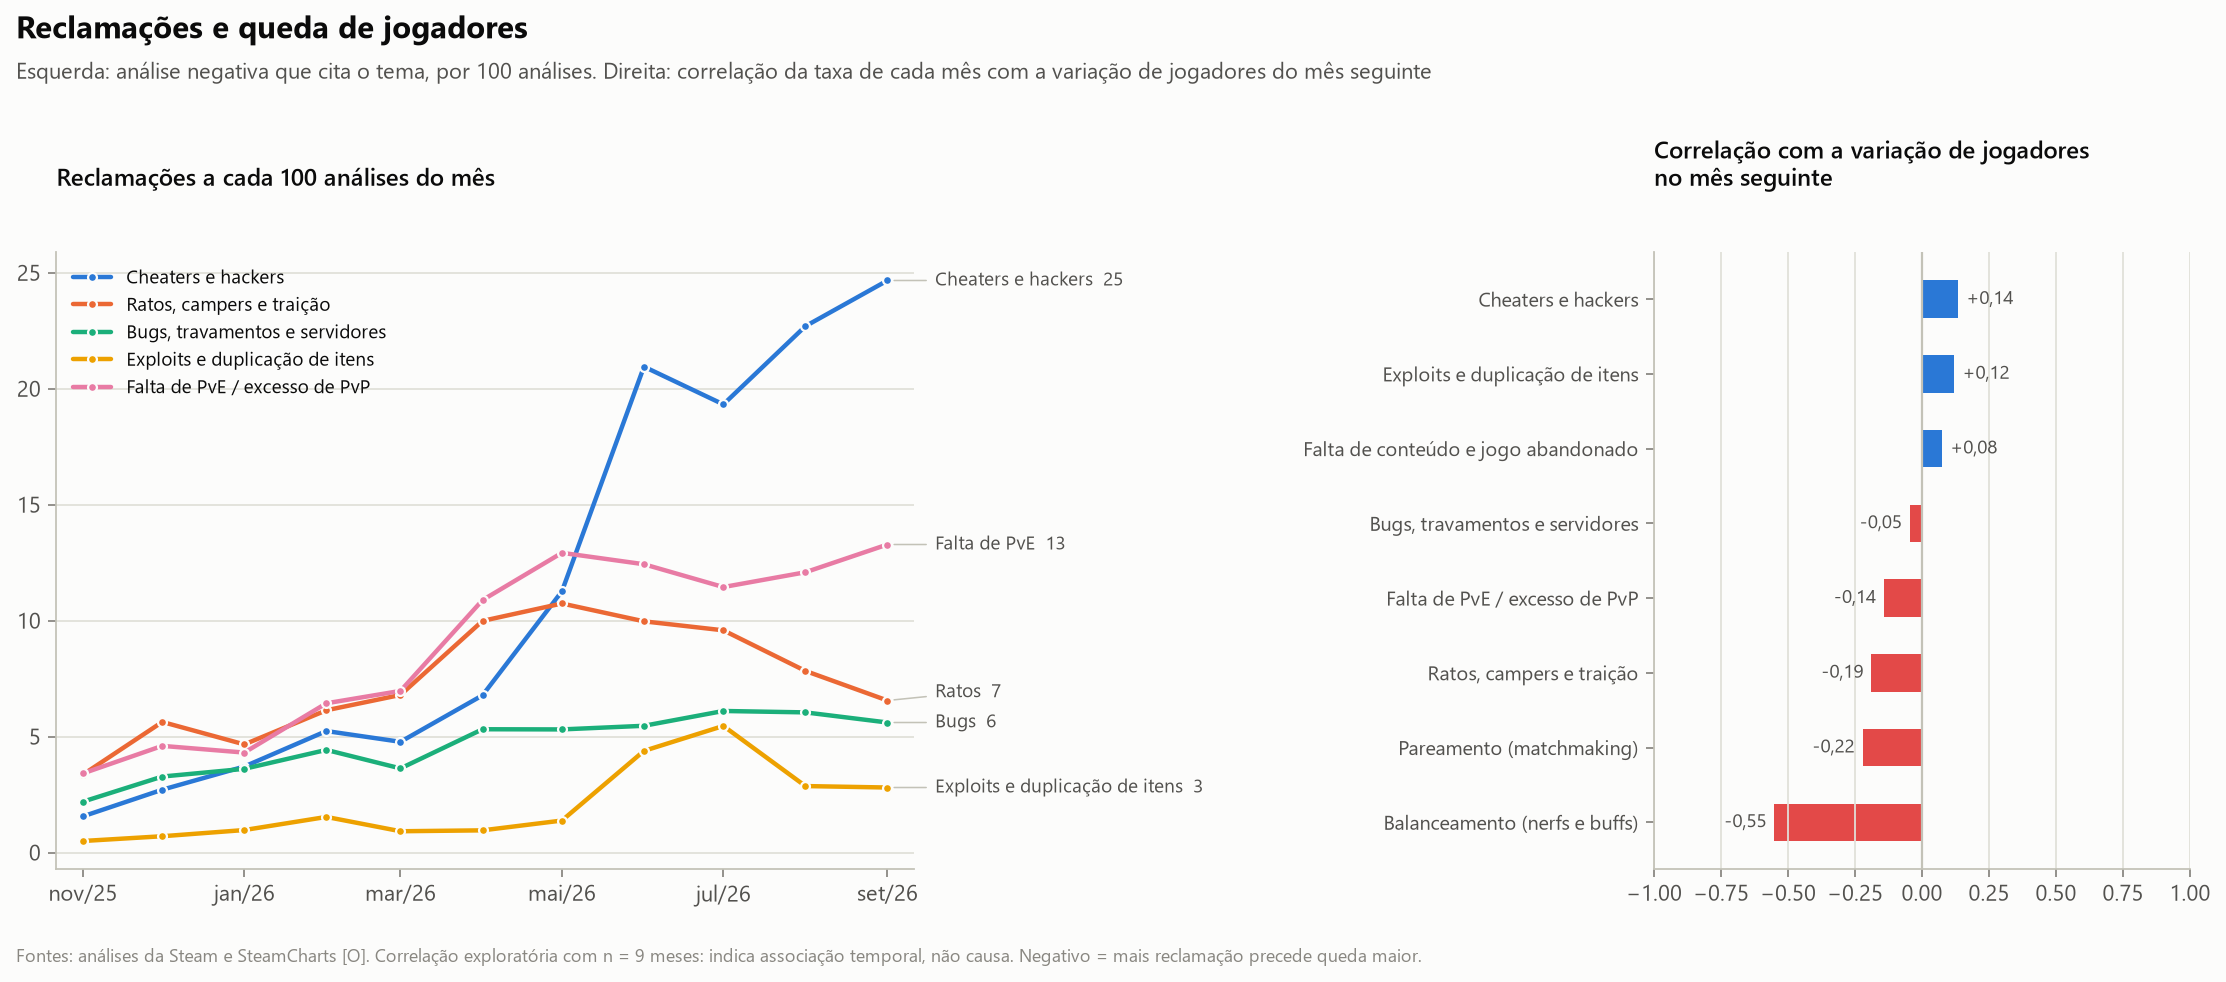

In [6]:
Image("../reports/figures/08e_reclamacoes_x_jogadores.png")

## Síntese

1. **Cheaters são o problema nº 1 hoje**: maior efeito no voto (−28 p.p.), de 9% para 43% das negativas, 25 reclamações a cada 100 análises em set/2026.
2. **Balanceamento é o gatilho das quedas**: é o único tema que antecede a perda de jogadores e o único associado a mais abandono; os nerfs coincidem com queda de jogadores e alta de reclamações.
3. **Falta de PvE é constante e vem de quem ainda joga**: ~1 em 5 negativas o ano todo, com menor associação ao abandono. É demanda reprimida, não motivo de saída.
4. **Ratos e bugs perderam peso relativo** com o tempo; exploits tiveram um pico em jun–jul/2026 (duplicação de itens).
5. **Falta de conteúdo está subestimada** pelo método (~46% de cobertura), e a Etapa 4 já mostrou que a pausa de conteúdo coincide com a queda.

**Implicações para a decisão (Etapa 9):** anti-cheat é pré-condição para recuperar a nota; congelar nerfs em armas populares e preferir buffs; o teste de PvE fala com um público que ainda está no jogo.